# Validación de hipótesis TFM

Continúa el Notebook 5: allí se identificaron los puntos débiles de los resultados (una sola semilla, ganadores con diferencias menores que la desviación entre pliegues, óptimos de reservorios extremadamente dispersos). Aquí se **lanzan entrenamientos nuevos** para ponerlos a prueba.

| Bloque | Pregunta |
|---|---|
| **A** | Si cambio la semilla (ruido de la señal y/o topología), ¿obtengo los mismos resultados? |
| **B** | Con la tarea fija, ¿cómo responde el error a N, ϱ, α y ridge, y cómo se mueve el óptimo con la dificultad? |
| **C** | ¿Se sostiene cada hipótesis de la lectura de las Tablas 1 y 2? (densidad igualada, baselines, suelo de ruido) |

## Índice

1. [Configuración y funciones](#1-configuración-y-funciones)
2. [Bloque A - Robustez frente a la semilla](#2-bloque-a---robustez-frente-a-la-semilla)
3. [Bloque B - Tarea fija, barrido de hiperparámetros](#3-bloque-b---tarea-fija-barrido-de-hiperparámetros)
4. [Bloque C - Validación de hipótesis](#4-bloque-c---validación-de-hipótesis)

## 1. Configuración y funciones

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"          # un hilo BLAS por proceso; el paralelismo lo da joblib

import random
import time
import warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats
from IPython.display import display
from sklearn.linear_model import Ridge as SkRidge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
import reservoirpy
from reservoirpy.nodes import Reservoir, Ridge

warnings.filterwarnings("ignore")

N_FOLDS = 10
LAG     = 10
T       = 15_000
N_JOBS  = -1
TOPOS   = ["ER", "WS", "BA"]
SIGS    = [f"S{i}" for i in range(1, 11)]

OUT   = Path("paper_outputs") / "nb6"
CACHE = OUT / "raw"
CACHE.mkdir(parents=True, exist_ok=True)

# Hiperparámetros ESN por señal (Tabla 2 del Notebook 5)
ESN = {
    "S1":  dict(N=400, sr=1.3, lr=0.10, ridge=5e-2),
    "S2":  dict(N=300, sr=1.1, lr=0.05, ridge=5e-2),
    "S3":  dict(N=100, sr=0.9, lr=0.10, ridge=5e-2),
    "S4":  dict(N=100, sr=0.9, lr=0.10, ridge=5e-2),
    "S5":  dict(N=50,  sr=0.9, lr=0.10, ridge=5e-2),
    "S6":  dict(N=50,  sr=0.9, lr=0.10, ridge=5e-2),
    "S7":  dict(N=50,  sr=1.3, lr=0.10, ridge=5e-2),
    "S8":  dict(N=50,  sr=1.1, lr=0.10, ridge=5e-2),
    "S9":  dict(N=25,  sr=0.9, lr=0.10, ridge=1e-3),
    "S10": dict(N=25,  sr=1.3, lr=0.20, ridge=5e-2),
}
# Topologías "canónicas" de NB1/NB3 (óptimo sobre S1)
CANON = {"ER": dict(p=0.001), "WS": dict(k=2, p_rw=0.01), "BA": dict(m=1), "NONE": {}}
print(f"Salidas en {OUT}/   |   núcleos: {os.cpu_count()}")

Salidas en paper_outputs/nb6/   |   núcleos: 8


In [2]:
# Señales S1-S10 de NB3 con semilla controlable y funciones de trabajo (ver nb6_worker.py)
from nb6_worker import make_signals, get_signal, build_dataset, make_W, run_job

for _n in SIGS:
    print(f"{_n:4s} suelo de ruido (RMSE irreducible) = {get_signal(0, _n)[1]:.4f}")

S1   suelo de ruido (RMSE irreducible) = 0.0495
S2   suelo de ruido (RMSE irreducible) = 0.2192
S3   suelo de ruido (RMSE irreducible) = 0.5612
S4   suelo de ruido (RMSE irreducible) = 0.8506
S5   suelo de ruido (RMSE irreducible) = 1.1894
S6   suelo de ruido (RMSE irreducible) = 1.5050
S7   suelo de ruido (RMSE irreducible) = 1.7922
S8   suelo de ruido (RMSE irreducible) = 2.2008
S9   suelo de ruido (RMSE irreducible) = 3.4458


S10  suelo de ruido (RMSE irreducible) = 4.2536


In [3]:
def job(exp, signal, sig_seed, topo_seed, topo, tp, variant, N, sr, lr, ridge, washout=10, **extra):
    d = dict(exp=exp, signal=signal, sig_seed=sig_seed, topo_seed=topo_seed, topo=topo,
             p=tp.get("p", np.nan), k=tp.get("k", np.nan), p_rw=tp.get("p_rw", np.nan), m=tp.get("m", np.nan),
             variant=variant, N=N, sr=sr, lr=lr, ridge=ridge, washout=washout)
    d.update(extra)
    return d


def run_jobs(name, jobs):
    f = CACHE / f"{name}.csv"
    if f.exists():
        print(f"[{name}] reutilizando {f}")
        return pd.read_csv(f)
    jobs = list(jobs)
    random.Random(0).shuffle(jobs)
    t0 = time.time()
    print(f"[{name}] {len(jobs)} evaluaciones de {N_FOLDS} pliegues ...")
    df = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=1)(delayed(run_job)(j) for j in jobs))
    df.to_csv(f, index=False)
    print(f"[{name}] hecho en {(time.time() - t0) / 60:.1f} min  (fallos: {int(df['rmse'].isna().sum())})")
    return df


def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); out = np.empty_like(p); run = 0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); out[i] = min(1, run)
    return out

def stars(p):
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"

## 2. Bloque A - Pruebas con distintas semillas

**Pregunta:** si cambio la semilla del ruido de la señal y de la topología (grafo, pesos y matriz de entrada), ¿obtengo los mismos resultados que en las Tablas 1-2?

Se prueba con 10 semillas (0-9). Cada una cambia a la vez el ruido de la señal y la topología. Las 10 señales S1-S10 con sus hiperparámetros de la Tabla 2 y las mejores topologías (ER p=0.001, WS k=2 / p_rw=0.01, BA m=1).

- **Existen dos variantes de reservorio para probar también el efecto de normalización de sr:**
  - `asis`: protocolo de NB1-NB4. `Reservoir(W=W, lr=lr)` **no reescala** W, así que `sr` **no se aplica** y los pesos son `randn` sin normalizar.
  - `scaled`: W reescalada a radio espectral `sr`, como asume la teoría de ESN.

- **Controles:** tres modelos de referencia (*baselines*) que se entrenan y evalúan igual que las ESN, con los mismos 10 pliegues. Sirven para saber cuánto aporta de verdad el reservorio y su topología. Van de menos a más capacidad:

| Control | Qué hace | Qué responde |
|---|---|---|
| `PERS` (persistencia) | Predice que el siguiente valor es igual al último: ŷ(t) = s(t−1). No entrena nada. | Es el listón mínimo. Si una ESN no lo supera, no ha aprendido nada útil. |
| `LIN` (ridge lineal) | Regresión ridge (α=1) directamente sobre los 10 retardos estandarizados. Es un modelo autorregresivo lineal AR(10). | ¿Hace falta un reservorio no lineal, o basta una combinación lineal de los últimos 10 valores? |
| `NONE` (sin recurrencia) | Una ESN con la matriz de pesos del reservorio W=0. Las neuronas no se conectan entre sí. | Aísla el efecto de la topología: la entrada, la tanh, la fuga y el ridge siguen ahí. |

In [4]:
# ---------------------------------------------------------------------------
# A: semillas acopladas, todas las señales, 4 topologías x 2 variantes + baselines
# ---------------------------------------------------------------------------
jobs = []
for s in range(10):
    for sig in SIGS:
        e = ESN[sig]
        for topo in TOPOS:
            for var in ("asis", "scaled"):
                jobs.append(job("A", sig, s, s, topo, CANON[topo], var, e["N"], e["sr"], e["lr"], e["ridge"]))
        jobs.append(job("A", sig, s, s, "NONE", {}, "asis", e["N"], e["sr"], e["lr"], e["ridge"]))
        for b in ("PERS", "LIN"):
            jobs.append(job("A", sig, s, s, b, {}, "asis", e["N"], e["sr"], e["lr"], e["ridge"]))
dfA = run_jobs("A_seeds", jobs)
print(dfA.groupby(["topo", "variant"]).rmse.count().unstack())

[A_seeds] reutilizando paper_outputs/nb6/raw/A_seeds.csv
variant   asis  scaled
topo                  
BA       100.0   100.0
ER       100.0   100.0
LIN      100.0     NaN
NONE     100.0     NaN
PERS     100.0     NaN
WS       100.0   100.0


In [5]:
# ---------------------------------------------------------------------------
# A: tabla media ± std ENTRE SEMILLAS por señal x topología
# ---------------------------------------------------------------------------
def seed_summary(df, variant):
    d = df[(df.variant == variant) | (df.topo.isin(["NONE", "PERS", "LIN"]))]
    g = d.groupby(["signal", "topo"]).rmse.agg(["mean", "std"]).unstack("topo")
    return g.reindex(SIGS)

for var in ("asis", "scaled"):
    g = seed_summary(dfA, var)
    cols = TOPOS + ["NONE", "LIN", "PERS"]
    tab = pd.DataFrame({t: [f"{g['mean'][t][s]:.4f} ± {g['std'][t][s]:.4f}" for s in SIGS] for t in cols}, index=SIGS)
    floor = [get_signal(0, s)[1] for s in SIGS]
    tab.insert(0, "suelo", [f"{f:.3f}" for f in floor])
    print(f"\n=== Variante '{var}': RMSE medio ± std entre 10 semillas ===")
    display(tab)
    tab.to_csv(OUT / f"A_seed_table_{var}.csv")


=== Variante 'asis': RMSE medio ± std entre 10 semillas ===


,suelo,ER,WS,BA,NONE,LIN,PERS
S1,0.049,0.0593 ± 0.0006,0.0575 ± 0.0021,0.0574 ± 0.0011,0.0660 ± 0.0005,0.0694 ± 0.0004,0.1148 ± 0.0004
S2,0.219,0.2559 ± 0.0018,0.2716 ± 0.0156,0.2639 ± 0.0072,0.2659 ± 0.0016,0.2650 ± 0.0011,0.3239 ± 0.0014
S3,0.561,0.6329 ± 0.0031,0.6321 ± 0.0100,0.6304 ± 0.0111,0.6400 ± 0.0032,0.6446 ± 0.0032,0.7966 ± 0.0044
S4,0.851,0.9455 ± 0.0052,0.9424 ± 0.0129,0.9396 ± 0.0132,0.9488 ± 0.0058,0.9572 ± 0.0053,1.2047 ± 0.0084
S5,1.189,1.3061 ± 0.0083,1.2917 ± 0.0136,1.2917 ± 0.0059,1.3058 ± 0.0085,1.3127 ± 0.0076,1.6964 ± 0.0120
S6,1.505,1.6104 ± 0.0080,1.5932 ± 0.0075,1.5978 ± 0.0078,1.6108 ± 0.0082,1.6149 ± 0.0079,2.1170 ± 0.0126
S7,1.792,1.9270 ± 0.0119,1.9134 ± 0.0084,1.9192 ± 0.0102,1.9285 ± 0.0115,1.9288 ± 0.0100,2.5582 ± 0.0219
S8,2.201,2.3365 ± 0.0132,2.3254 ± 0.0290,2.3276 ± 0.0128,2.3395 ± 0.0136,2.3377 ± 0.0129,3.1121 ± 0.0205
S9,3.446,3.5693 ± 0.0213,3.5549 ± 0.0225,3.5570 ± 0.0199,3.5717 ± 0.0235,3.5643 ± 0.0229,4.8631 ± 0.0358
S10,4.254,4.3973 ± 0.0281,4.3875 ± 0.0264,4.3851 ± 0.0269,4.3997 ± 0.0278,4.3875 ± 0.0273,6.0045 ± 0.0391



=== Variante 'scaled': RMSE medio ± std entre 10 semillas ===


,suelo,ER,WS,BA,NONE,LIN,PERS
S1,0.049,0.0593 ± 0.0006,0.0569 ± 0.0009,0.0578 ± 0.0009,0.0660 ± 0.0005,0.0694 ± 0.0004,0.1148 ± 0.0004
S2,0.219,0.2558 ± 0.0018,0.2517 ± 0.0012,0.2517 ± 0.0016,0.2659 ± 0.0016,0.2650 ± 0.0011,0.3239 ± 0.0014
S3,0.561,0.6329 ± 0.0031,0.6198 ± 0.0031,0.6220 ± 0.0029,0.6400 ± 0.0032,0.6446 ± 0.0032,0.7966 ± 0.0044
S4,0.851,0.9455 ± 0.0052,0.9301 ± 0.0048,0.9334 ± 0.0058,0.9488 ± 0.0058,0.9572 ± 0.0053,1.2047 ± 0.0084
S5,1.189,1.3061 ± 0.0083,1.2888 ± 0.0071,1.2896 ± 0.0082,1.3058 ± 0.0085,1.3127 ± 0.0076,1.6964 ± 0.0120
S6,1.505,1.6104 ± 0.0080,1.5938 ± 0.0073,1.5955 ± 0.0073,1.6108 ± 0.0082,1.6149 ± 0.0079,2.1170 ± 0.0126
S7,1.792,1.9270 ± 0.0119,1.9096 ± 0.0094,1.9127 ± 0.0097,1.9285 ± 0.0115,1.9288 ± 0.0100,2.5582 ± 0.0219
S8,2.201,2.3365 ± 0.0132,2.3166 ± 0.0121,2.3193 ± 0.0137,2.3395 ± 0.0136,2.3377 ± 0.0129,3.1121 ± 0.0205
S9,3.446,3.5693 ± 0.0213,3.5561 ± 0.0223,3.5561 ± 0.0199,3.5717 ± 0.0235,3.5643 ± 0.0229,4.8631 ± 0.0358
S10,4.254,4.3973 ± 0.0281,4.3862 ± 0.0268,4.3915 ± 0.0397,4.3997 ± 0.0278,4.3875 ± 0.0273,6.0045 ± 0.0391


In [6]:
# ---------------------------------------------------------------------------
# A: ¿se mantiene el ganador? Victorias por semilla, Friedman y Wilcoxon pareado (Holm)
# ---------------------------------------------------------------------------
def winner_tests(df, variant, topos=TOPOS):
    rows = []
    d = df[(df.variant == variant) & df.topo.isin(topos)]
    for sig in SIGS:
        P = d[d.signal == sig].pivot(index="sig_seed", columns="topo", values="rmse")[topos]
        wins = P.idxmin(axis=1).value_counts().reindex(topos, fill_value=0)
        fr = stats.friedmanchisquare(*[P[t] for t in topos]).pvalue
        pairs = [("ER", "WS"), ("ER", "BA"), ("WS", "BA")]
        pw = [stats.wilcoxon(P[a], P[b]).pvalue for a, b in pairs]
        ph = holm(pw)
        rows.append(dict(signal=sig, **{f"wins_{t}": int(wins[t]) for t in topos},
                         mean_winner=P.mean().idxmin(), friedman_p=fr,
                         **{f"{a}-{b}": f"{(P[a] - P[b]).mean() / P[[a, b]].mean().mean() * 100:+.2f}% ({stars(p)})"
                            for (a, b), p in zip(pairs, ph)}))
    return pd.DataFrame(rows).set_index("signal")

for var in ("asis", "scaled"):
    wt = winner_tests(dfA, var)
    print(f"\n=== Variante '{var}' - victorias en 10 semillas (por señal) y tests ===")
    print("Diferencia relativa media (a-b) entre topologías; significación Wilcoxon pareado con Holm (n=10 semillas)")
    display(wt.style.format({"friedman_p": "{:.3g}"}))
    wt.to_csv(OUT / f"A_winner_tests_{var}.csv")
    print("Victorias totales (señal x semilla):", {t: int(wt[f'wins_{t}'].sum()) for t in TOPOS},
          "| señales con Friedman p<0.05:", int((wt.friedman_p < .05).sum()), "/ 10")


=== Variante 'asis' - victorias en 10 semillas (por señal) y tests ===
Diferencia relativa media (a-b) entre topologías; significación Wilcoxon pareado con Holm (n=10 semillas)


,wins_ER,wins_WS,wins_BA,mean_winner,friedman_p,ER-WS,ER-BA,WS-BA
signal,,,,,,,,
S1,0,4,6,BA,0.0136,+3.05% (ns),+3.31% (**),+0.26% (ns)
S2,10,0,0,ER,0.000225,-5.96% (**),-3.08% (**),+2.88% (ns)
S3,1,3,6,BA,0.407,+0.12% (ns),+0.39% (ns),+0.27% (ns)
S4,0,5,5,BA,0.15,+0.33% (ns),+0.63% (ns),+0.30% (ns)
S5,0,7,3,BA,0.00184,+1.10% (*),+1.11% (**),+0.00% (ns)
S6,0,7,3,WS,0.000371,+1.07% (**),+0.78% (**),-0.29% (ns)
S7,0,6,4,WS,0.0136,+0.71% (**),+0.41% (ns),-0.30% (ns)
S8,0,8,2,WS,0.00745,+0.47% (ns),+0.38% (ns),-0.10% (ns)
S9,0,7,3,WS,0.00123,+0.40% (**),+0.35% (**),-0.06% (ns)


Victorias totales (señal x semilla): {'ER': 11, 'WS': 49, 'BA': 40} | señales con Friedman p<0.05: 8 / 10

=== Variante 'scaled' - victorias en 10 semillas (por señal) y tests ===
Diferencia relativa media (a-b) entre topologías; significación Wilcoxon pareado con Holm (n=10 semillas)


,wins_ER,wins_WS,wins_BA,mean_winner,friedman_p,ER-WS,ER-BA,WS-BA
signal,,,,,,,,
S1,0,7,3,WS,0.000371,+4.16% (**),+2.54% (**),-1.62% (ns)
S2,0,6,4,WS,0.0005,+1.62% (**),+1.61% (**),-0.01% (ns)
S3,0,10,0,WS,4.54e-05,+2.09% (**),+1.73% (**),-0.35% (**)
S4,0,9,1,WS,0.000112,+1.64% (**),+1.29% (**),-0.35% (*)
S5,0,6,4,WS,0.0005,+1.34% (**),+1.27% (**),-0.07% (ns)
S6,0,7,3,WS,0.000371,+1.04% (**),+0.93% (**),-0.11% (ns)
S7,0,8,2,WS,0.000225,+0.91% (**),+0.75% (**),-0.16% (ns)
S8,0,5,5,WS,0.000553,+0.85% (**),+0.74% (**),-0.12% (ns)
S9,0,6,4,BA,0.0005,+0.37% (**),+0.37% (**),+0.00% (ns)


Victorias totales (señal x semilla): {'ER': 0, 'WS': 70, 'BA': 30} | señales con Friedman p<0.05: 10 / 10


In [7]:
# ---------------------------------------------------------------------------
# A: ranking global entre señales (Friedman + diferencia crítica de Nemenyi)
# ---------------------------------------------------------------------------
def nemenyi_cd(k, n, alpha=0.05):
    q = stats.studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2)
    return q * np.sqrt(k * (k + 1) / (6 * n))

for var in ("asis", "scaled"):
    for label, topos in (("3 topologías", TOPOS), ("3 topologías + sin recurrencia", TOPOS + ["NONE"])):
        d = dfA[((dfA.variant == var) | (dfA.topo == "NONE")) & dfA.topo.isin(topos)]
        M = d.groupby(["signal", "topo"]).rmse.mean().unstack()[topos].reindex(SIGS)
        ranks = M.rank(axis=1)
        fp = stats.friedmanchisquare(*[M[t] for t in topos]).pvalue
        cd = nemenyi_cd(len(topos), len(SIGS))
        print(f"[{var:6s}] {label:32s} rangos medios: " + "  ".join(f"{t}={ranks[t].mean():.2f}" for t in topos)
              + f"   Friedman p={fp:.3g}   CD(Nemenyi)={cd:.2f}")

[asis  ] 3 topologías                     rangos medios: ER=2.80  WS=1.70  BA=1.50   Friedman p=0.00745   CD(Nemenyi)=1.05
[asis  ] 3 topologías + sin recurrencia   rangos medios: ER=2.90  WS=1.80  BA=1.50  NONE=3.80   Friedman p=0.000167   CD(Nemenyi)=1.48
[scaled] 3 topologías                     rangos medios: ER=3.00  WS=1.10  BA=1.90   Friedman p=0.000112   CD(Nemenyi)=1.05


[scaled] 3 topologías + sin recurrencia   rangos medios: ER=3.10  WS=1.10  BA=1.90  NONE=3.90   Friedman p=3.92e-06   CD(Nemenyi)=1.48


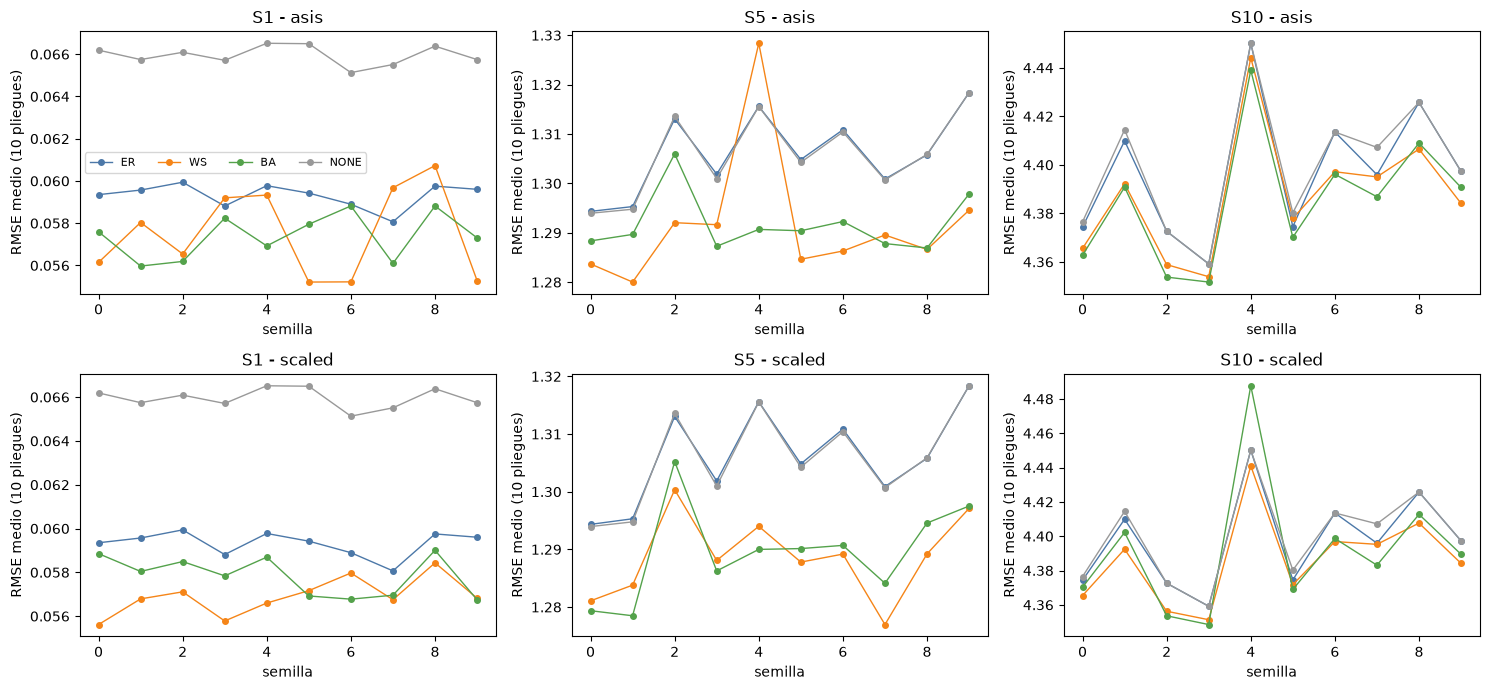

In [9]:
# ---------------------------------------------------------------------------
# Figura A: RMSE por semilla y topología (variante 'asis' y 'scaled'), señales S1, S5, S10
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
colors = {"ER": "#4c78a8", "WS": "#f58518", "BA": "#54a24b", "NONE": "#999999"}
for r, var in enumerate(("asis", "scaled")):
    for c, sig in enumerate(("S1", "S5", "S10")):
        ax = axes[r, c]
        for topo in TOPOS + ["NONE"]:
            d = dfA[(dfA.signal == sig) & (dfA.topo == topo) & ((dfA.variant == var) | (topo == "NONE"))].sort_values("sig_seed")
            ax.plot(d.sig_seed, d.rmse, "o-", ms=4, lw=1, color=colors[topo], label=topo)
        ax.set_title(f"{sig} - {var}"); ax.set_xlabel("semilla"); ax.set_ylabel("RMSE medio (10 pliegues)")
axes[0, 0].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "A_rmse_per_seed.png", dpi=130, bbox_inches="tight"); plt.show()

### Conclusiones Bloque A

- **El ganador depende de si se normaliza sr, no solo de la semilla.** Con el protocolo `asis` el ganador cambia entre señales y semillas: el ganador por media de semillas es BA en S1, S3, S4, S5 y S10, ER en S2 (10/10 semillas) y WS en S6-S9, con muchos empates por semilla. **La conclusión de la tabla de que "WS gana 7/13" parece resultado robusto** del todo.
- **Con el radio espectral normalizado (`scaled`) el patrón es estable**: WS es el mejor en 9 de 10 señales por media de semillas y ER es siempre el peor (Friedman p<0.002 en las diez; Wilcoxon pareado con Holm). Pero **las diferencias son pequeñas y se encogen con la dificultad**: WS vs ER pasa de +4.2 % (S1) a +0.25 % (S10), y WS vs BA no es significativo en la mayoría de señales (|dif| ≤ 0.35 %).


## 3. Bloque B - Tarea fija, y variar hiperparámetros

**Pregunta:** con la tarea fija, ¿cómo cambia el error al variar los hiperparámetros ESN, y cómo se mueve el óptimo con la dificultad (σ del ruido de S1 a S10)?


Como "dificultad" se usa el **suelo de ruido** de cada señal (RMS del término aleatorio, ver §1), que es exactamente el error mínimo alcanzable.

In [10]:
# ---------------------------------------------------------------------------
# B: barridos one-at-a-time sobre las 10 señales
# ---------------------------------------------------------------------------
BASE = dict(N=100, sr=1.0, lr=0.1, ridge=0.05)
SWEEP = {
    "N":     [25, 50, 100, 200, 400],
    "sr":    [0.5, 0.7, 0.9, 1.0, 1.1, 1.3, 1.5],
    "lr":    [0.02, 0.05, 0.1, 0.2, 0.5, 1.0],
    "ridge": [1e-4, 1e-3, 1e-2, 5e-2, 0.2, 1.0, 10.0],
}
def deg2(topo, N):
    return {"ER": dict(p=2 / N), "WS": dict(k=2, p_rw=0.01), "BA": dict(m=1)}[topo]

cfgs = {tuple(sorted({**BASE, hp: v}.items())) for hp, vals in SWEEP.items() for v in vals}
jobs = []
for sig in SIGS:
    for cfg in cfgs:
        c = dict(cfg)
        for s in range(3):
            for topo in TOPOS:
                jobs.append(job("B", sig, s, s, topo, deg2(topo, c["N"]), "scaled", c["N"], c["sr"], c["lr"], c["ridge"]))
dfB = run_jobs("B_hp_sweeps", jobs)
dfB["floor"] = dfB.floor.round(6)
print(len(cfgs), "configuraciones únicas;", len(dfB), "evaluaciones")

[B_hp_sweeps] reutilizando paper_outputs/nb6/raw/B_hp_sweeps.csv
22 configuraciones únicas; 1980 evaluaciones


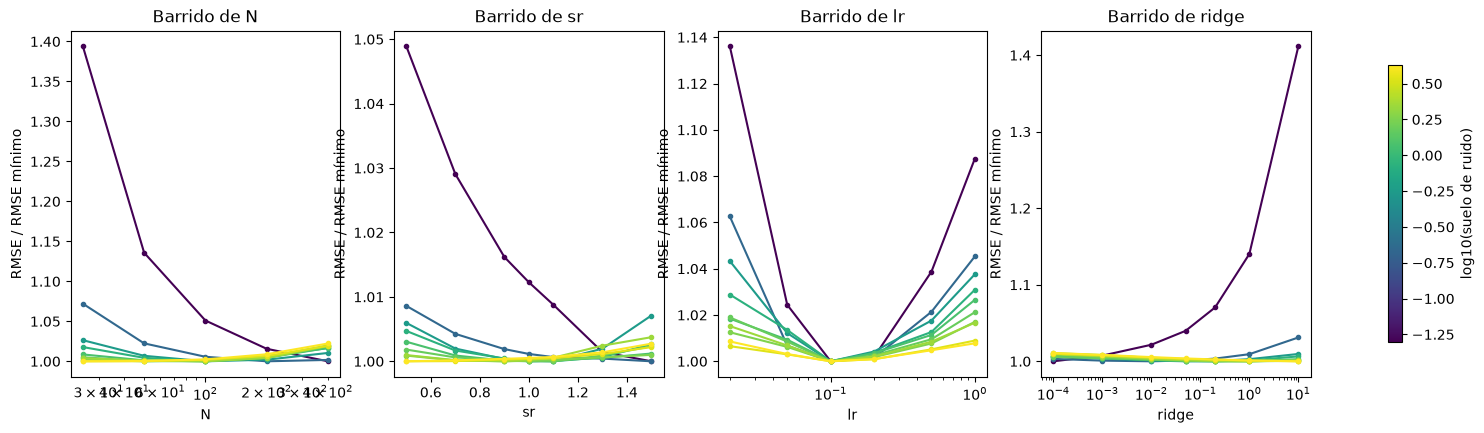

Valor óptimo (argmin del RMSE medio sobre topologías y semillas)


hp,N,sr,lr,ridge
signal,,,,
S1,400.0,1.5,0.1,0.0001
S2,200.0,1.5,0.1,0.0100
S3,100.0,1.0,0.1,0.0500
S4,100.0,1.1,0.1,0.2000
S5,100.0,1.0,0.1,0.2000
S6,100.0,1.1,0.1,1.0000
S7,50.0,0.9,0.1,1.0000
S8,100.0,0.9,0.1,1.0000
S9,25.0,0.5,0.1,10.0000


Sensibilidad = (RMSE máx / RMSE mín - 1) en %, dentro del rango barrido


hp,N,sr,lr,ridge
signal,,,,
S1,39.40,4.89,13.61,41.15
S2,7.21,0.86,6.26,3.11
S3,2.64,0.71,4.33,0.96
S4,1.78,0.47,3.09,0.73
S5,1.67,0.30,2.66,0.65
S6,1.90,0.23,2.12,0.57
S7,1.99,0.10,1.70,1.06
S8,1.92,0.37,1.67,0.90
S9,1.94,0.22,0.90,0.99


In [11]:
# ---------------------------------------------------------------------------
# B: curvas RMSE/mínimo por señal (color = suelo de ruido) y óptimo vs dificultad
# ---------------------------------------------------------------------------
floors = pd.Series({s: get_signal(0, s)[1] for s in SIGS})
cmap = plt.cm.viridis
norm = plt.Normalize(np.log10(floors.min()), np.log10(floors.max()))

def sweep_frame(hp):
    other = [h for h in SWEEP if h != hp]
    m = np.ones(len(dfB), bool)
    for h in other:
        m &= np.isclose(dfB[h], BASE[h])
    return dfB[m]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
opt_rows = []
for ax, hp in zip(axes, SWEEP):
    d = sweep_frame(hp)
    for sig in SIGS:
        g = d[d.signal == sig].groupby(hp).rmse.mean()
        ax.plot(g.index, g / g.min(), "o-", ms=3, color=cmap(norm(np.log10(floors[sig]))), label=sig)
        gs = d[d.signal == sig].groupby([hp, "sig_seed", "topo"]).rmse.mean().groupby(hp).agg(["mean", "std", "count"])
        best = gs["mean"].idxmin()
        se = gs.loc[best, "std"] / np.sqrt(gs.loc[best, "count"])
        within = gs.index[gs["mean"] <= gs.loc[best, "mean"] + se]
        opt_rows.append(dict(signal=sig, hp=hp, floor=floors[sig], optimum=best, parsimonious=within.min() if hp in ("N",) else (within.max() if hp == "ridge" else best),
                             sensitivity_pct=100 * (g.max() / g.min() - 1)))
    ax.set_xscale("log" if hp in ("N", "lr", "ridge") else "linear"); ax.set_xlabel(hp); ax.set_ylabel("RMSE / RMSE mínimo")
    ax.set_title(f"Barrido de {hp}")
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=axes, label="log10(suelo de ruido)", shrink=0.8)
plt.savefig(OUT / "B_hp_sweeps.png", dpi=130, bbox_inches="tight"); plt.show()

opt = pd.DataFrame(opt_rows)
opt.to_csv(OUT / "B_optimum_per_signal.csv", index=False)
print("Valor óptimo (argmin del RMSE medio sobre topologías y semillas)")
display(opt.pivot(index="signal", columns="hp", values="optimum").reindex(SIGS)[list(SWEEP)])
print("Sensibilidad = (RMSE máx / RMSE mín - 1) en %, dentro del rango barrido")
display(opt.pivot(index="signal", columns="hp", values="sensitivity_pct").reindex(SIGS)[list(SWEEP)].round(2))

In [12]:
# ---------------------------------------------------------------------------
# B: ¿el óptimo se mueve con la dificultad? Spearman óptimo ~ suelo de ruido
# ---------------------------------------------------------------------------
rows = []
for hp in SWEEP:
    o = opt[opt.hp == hp]
    for col in ("optimum", "parsimonious"):
        if col == "parsimonious" and hp not in ("N", "ridge"):
            continue
        rho, p = stats.spearmanr(o["floor"], o[col])
        rows.append(dict(hp=hp, criterio="argmin" if col == "optimum" else "1-SE (N menor / ridge mayor)",
                         spearman=rho, p=p, optimo_S1=float(o[o.signal == "S1"][col].iloc[0]),
                         optimo_S10=float(o[o.signal == "S10"][col].iloc[0])))
sp = pd.DataFrame(rows); sp.to_csv(OUT / "B_spearman_optimum_vs_difficulty.csv", index=False)
display(sp.style.format({"spearman": "{:+.2f}", "p": "{:.3g}"}))

# Topología x ϱ: ¿cambia el ranking de topologías con el hiperparámetro?
d = sweep_frame("sr").copy()
d["rel"] = d.rmse / d.groupby(["signal", "sig_seed", "sr"]).rmse.transform("mean")
tab = d.groupby(["sr", "topo"]).rel.mean().unstack()[TOPOS]
print("\nRMSE relativo al promedio de topologías, por valor de ϱ (media sobre señales y semillas; <1 = mejor que la media)")
display(tab.round(4))

,hp,criterio,spearman,p,optimo_S1,optimo_S10
0,N,argmin,-0.90,0.000463,400.000000,25.000000
1,N,1-SE (N menor / ridge mayor),-0.86,0.00141,400.000000,25.000000
2,sr,argmin,-0.91,0.000248,1.500000,0.500000
3,lr,argmin,+nan,nan,0.100000,0.100000
4,ridge,argmin,+0.98,4.85e-07,0.000100,10.000000
5,ridge,1-SE (N menor / ridge mayor),+0.91,0.000233,0.000100,10.000000



RMSE relativo al promedio de topologías, por valor de ϱ (media sobre señales y semillas; <1 = mejor que la media)


topo,ER,WS,BA
sr,,,
0.5,0.9977,1.0003,1.0020
0.7,0.9987,0.9996,1.0016
0.9,0.9998,0.9988,1.0014
1.0,1.0002,0.9984,1.0013
1.1,1.0007,0.9981,1.0012
1.3,1.0025,0.9969,1.0006
1.5,1.0057,0.9953,0.9991


## 4. Bloque C - Validación de hipótesis de las Tablas 1 y 2

| # | Hipótesis (lectura del Notebook 5) | Dónde se prueba |
|---|---|---|
| H1 | WS gana con ventaja pequeña; no se puede afirmar que una topología sea mejor | A (ya arriba) |
| H2 | La ventaja depende de la **densidad efectiva**, no de la familia topológica | C1 (densidad igualada) |
| H3 | Los reservorios óptimos son extremadamente dispersos (ER p≤0.001, WS k=2, BA m=1) | C1, C2 |
| H4 | El tamaño óptimo N decrece con la dificultad | B (barrido de N) |
| H5 | α=0.1 es casi universal; ϱ no muestra patrón (superficie plana) | B (α, ϱ) |
| H6 | El RMSE crece ≈ linealmente con σ; en señales difíciles domina el ruido irreducible | C3 |
| H7 | Las diferencias entre topologías se diluyen al aumentar el ruido | C3 |
| H8 | El reservorio aporta algo frente a baselines triviales | A (NONE, LIN, PERS) |

### C1 - Comparación a densidad igualada (H2, H3)

In [13]:
# ---------------------------------------------------------------------------
# C1: RMSE frente al grado medio de entrada (N=200), mismas ESN para las tres topologías
# ---------------------------------------------------------------------------
N_D, sr_D, lr_D, rg_D = 200, 1.0, 0.1, 0.05
DEG = {"ER": [0.25, 0.5, 1, 2, 4, 8, 16, 32], "WS": [2, 4, 8, 16, 32], "BA": [1, 2, 4, 8, 16]}   # BA: m (grado = 2m)
def tp_of(topo, v):
    return {"ER": dict(p=v / N_D), "WS": dict(k=v, p_rw=0.01), "BA": dict(m=v)}[topo]

jobs = []
for sig in ("S1", "S5", "S10"):
    for s in range(5):
        jobs.append(job("C1", sig, s, s, "NONE", {}, "asis", N_D, sr_D, lr_D, rg_D, nominal_deg=0.0))
        for topo, vals in DEG.items():
            for v in vals:
                for var in ("asis", "scaled"):
                    jobs.append(job("C1", sig, s, s, topo, tp_of(topo, v), var, N_D, sr_D, lr_D, rg_D,
                                    nominal_deg=float(2 * v if topo == "BA" else v)))
dfC1 = run_jobs("C1_density", jobs)
dfC1["mean_deg"] = dfC1.n_edges / dfC1.N

[C1_density] reutilizando paper_outputs/nb6/raw/C1_density.csv


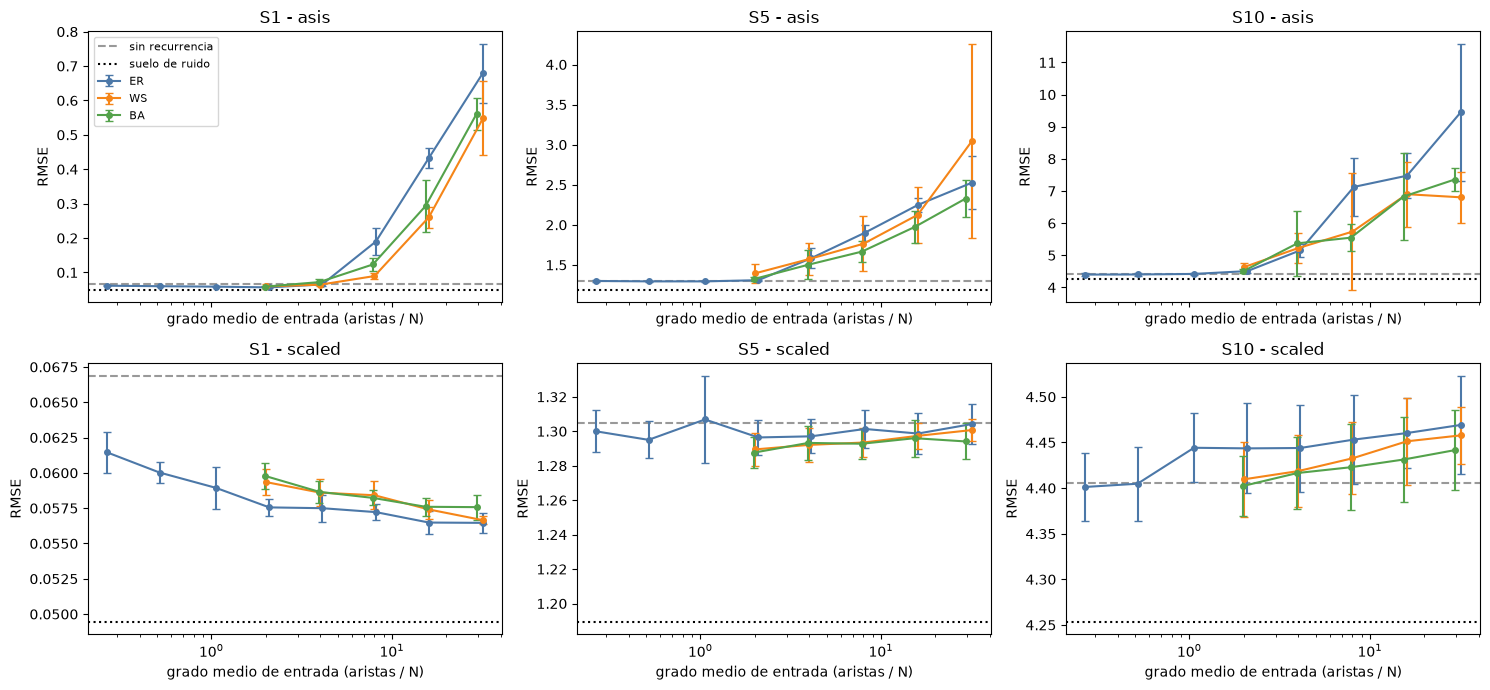

Proporción de la varianza del RMSE explicada por cada factor (grados comunes 2-32, N=200)


,signal,variant,eta2_grado,eta2_topologia
0,S1,asis,0.917,0.026
1,S1,scaled,0.379,0.231
2,S10,asis,0.558,0.063
3,S10,scaled,0.099,0.088
4,S5,asis,0.609,0.026
5,S5,scaled,0.087,0.087



Radio espectral natural medio de W (protocolo NB1-NB4, sin reescalar), por grado nominal


topo,BA,ER,WS
nominal_deg,,,
0.25,NaN,0.00,NaN
0.50,NaN,0.00,NaN
1.00,NaN,0.71,NaN
2.00,2.82,1.38,2.43
4.00,3.06,2.09,2.97
8.00,4.07,2.94,3.66
16.00,5.11,4.15,4.54
32.00,6.82,5.91,6.04


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for r, var in enumerate(("asis", "scaled")):
    for c, sig in enumerate(("S1", "S5", "S10")):
        ax = axes[r, c]
        none = dfC1[(dfC1.signal == sig) & (dfC1.topo == "NONE")].rmse
        ax.axhline(none.mean(), color="#999999", ls="--", label="sin recurrencia")
        ax.axhline(get_signal(0, sig)[1], color="k", ls=":", label="suelo de ruido")
        for topo in TOPOS:
            g = dfC1[(dfC1.signal == sig) & (dfC1.topo == topo) & (dfC1.variant == var)]
            m = g.groupby("nominal_deg").agg(x=("mean_deg", "mean"), y=("rmse", "mean"), s=("rmse", "std"))
            ax.errorbar(m.x.clip(lower=0.1), m.y, m.s, marker="o", ms=4, capsize=3, color=colors[topo], label=topo)
        ax.set_xscale("log"); ax.set_title(f"{sig} - {var}"); ax.set_xlabel("grado medio de entrada (aristas / N)"); ax.set_ylabel("RMSE")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "C1_density.png", dpi=130, bbox_inches="tight"); plt.show()

# Descomposición de varianza a grados nominales comunes {2,4,8,16,32}: ¿pesa más el grado o la familia?
rows = []
common = [2, 4, 8, 16, 32]
for (sig, var), g in dfC1[dfC1.topo.isin(TOPOS)].groupby(["signal", "variant"]):
    g = g[g.nominal_deg.isin(common)]
    gm = g.rmse.mean(); ss_tot = ((g.rmse - gm) ** 2).sum()
    ss_deg = sum(len(x) * (x.rmse.mean() - gm) ** 2 for _, x in g.groupby("nominal_deg"))
    ss_top = sum(len(x) * (x.rmse.mean() - gm) ** 2 for _, x in g.groupby("topo"))
    rows.append(dict(signal=sig, variant=var, eta2_grado=ss_deg / ss_tot, eta2_topologia=ss_top / ss_tot))
eta = pd.DataFrame(rows); eta.to_csv(OUT / "C1_eta2.csv", index=False)
print("Proporción de la varianza del RMSE explicada por cada factor (grados comunes 2-32, N=200)")
display(eta.round(3))

# Diagnóstico: radio espectral natural (sin reescalar) de los pesos randn
rho_tab = dfC1[(dfC1.variant == "asis") & dfC1.topo.isin(TOPOS)].groupby(["topo", "nominal_deg"]).rho_raw.mean().unstack(0)
print("\nRadio espectral natural medio de W (protocolo NB1-NB4, sin reescalar), por grado nominal")
display(rho_tab.round(2))

### C2 - Los óptimos 'canónicos' en las señales de NB3 (H3)

In [15]:
# ER p=0.001 con N pequeño no genera casi aristas: ¿es en la práctica un reservorio vacío?
ed = dfA[(dfA.topo.isin(TOPOS)) & (dfA.variant == "asis")].groupby(["signal", "topo"]).n_edges.mean().unstack()[TOPOS].reindex(SIGS)
ed.insert(0, "N", [ESN[s]["N"] for s in SIGS])
print("Número medio de aristas en las configuraciones canónicas de NB3 (10 semillas)")
display(ed.round(1))
# Diferencia ER vs sin recurrencia (variante asis)
P = dfA[dfA.variant.eq("asis") | dfA.topo.eq("NONE")].pivot_table(index=["signal", "sig_seed"], columns="topo", values="rmse")
rows = []
for sig in SIGS:
    d = (P.loc[sig, "ER"] - P.loc[sig, "NONE"])
    rows.append(dict(signal=sig, dif_ER_vs_NONE_pct=100 * d.mean() / P.loc[sig, "NONE"].mean(), p_wilcoxon=stats.wilcoxon(P.loc[sig, "ER"], P.loc[sig, "NONE"]).pvalue if d.abs().sum() > 0 else 1.0))
display(pd.DataFrame(rows).set_index("signal").round(4))

Número medio de aristas en las configuraciones canónicas de NB3 (10 semillas)


topo,N,ER,WS,BA
signal,,,,
S1,400,161.6,800.0,798.0
S2,300,93.5,600.0,598.0
S3,100,11.5,200.0,198.0
S4,100,11.5,200.0,198.0
S5,50,2.5,100.0,98.0
S6,50,2.5,100.0,98.0
S7,50,2.5,100.0,98.0
S8,50,2.5,100.0,98.0
S9,25,0.9,50.0,48.0


,dif_ER_vs_NONE_pct,p_wilcoxon
signal,,
S1,-10.0559,0.0020
S2,-3.7762,0.0020
S3,-1.1048,0.0020
S4,-0.3518,0.0020
S5,0.0187,0.1055
S6,-0.0274,0.0195
S7,-0.0760,0.0020
S8,-0.1269,0.0039
S9,-0.0659,0.1250


### C3 - Suelo de ruido y dilución de las diferencias (H6, H7, H8)

,suelo,mejor ESN,NONE,LIN,PERS,mejor/suelo,exceso_RMSE2,ESN vs LIN %,ESN vs NONE %,dispersion topologías % (asis)
S1,0.0499,0.0569,0.0660,0.0694,0.1148,1.1407,0.0007,17.9606,13.7177,3.3614
S2,0.2195,0.2517,0.2659,0.2650,0.3239,1.1468,0.0152,5.0023,5.3367,6.1432
S3,0.5599,0.6198,0.6400,0.6446,0.7966,1.1071,0.0707,3.8384,3.1479,0.3929
S4,0.8494,0.9301,0.9488,0.9572,1.2047,1.0951,0.1437,2.8244,1.9681,0.6302
S5,1.1982,1.2888,1.3058,1.3127,1.6964,1.0756,0.2252,1.8243,1.3086,1.1121
S6,1.4961,1.5932,1.6108,1.6149,2.1170,1.0649,0.3000,1.3430,1.0928,1.0772
S7,1.8044,1.9096,1.9285,1.9288,2.5582,1.0583,0.3907,0.9945,0.9795,0.7141
S8,2.2007,2.3166,2.3395,2.3377,3.1121,1.0527,0.5237,0.9019,0.9753,0.4760
S9,3.4431,3.5549,3.5717,3.5643,4.8631,1.0325,0.7825,0.2635,0.4692,0.4051
S10,4.2627,4.3851,4.3997,4.3875,6.0045,1.0287,1.0582,0.0550,0.3322,0.2791


RMSE_mejor = 0.045 + 1.023 * suelo     R2 = 0.9998
Spearman(suelo, dispersión entre topologías) = -0.66  (p=0.0376)


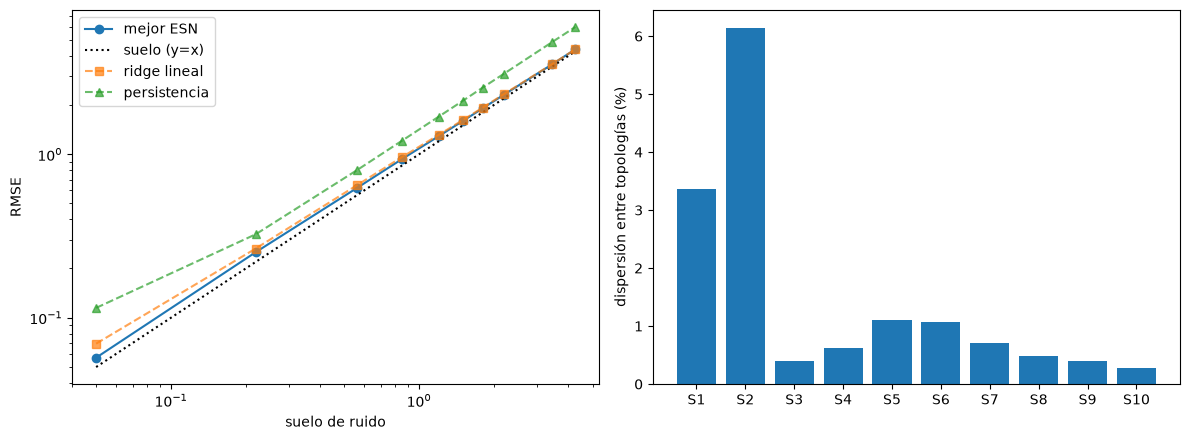

In [16]:
# ---------------------------------------------------------------------------
# C3: RMSE vs suelo de ruido, exceso de error y tamaño de las diferencias entre topologías
# ---------------------------------------------------------------------------
M = dfA.copy()
M["cfg"] = np.where(M.topo.isin(["NONE", "LIN", "PERS"]), M.topo, M.topo + "_" + M.variant)
mean = M.groupby(["signal", "cfg"]).rmse.mean().unstack().reindex(SIGS)
fl = pd.Series({s: M[M.signal == s].floor.mean() for s in SIGS})

tab = pd.DataFrame({"suelo": fl, "mejor ESN": mean[[c for c in mean if c.split("_")[0] in TOPOS]].min(axis=1),
                    "NONE": mean["NONE"], "LIN": mean["LIN"], "PERS": mean["PERS"]})
tab["mejor/suelo"] = tab["mejor ESN"] / tab["suelo"]
tab["exceso_RMSE2"] = tab["mejor ESN"] ** 2 - tab["suelo"] ** 2
tab["ESN vs LIN %"] = 100 * (tab["LIN"] - tab["mejor ESN"]) / tab["LIN"]
tab["ESN vs NONE %"] = 100 * (tab["NONE"] - tab["mejor ESN"]) / tab["NONE"]
spread = mean[[c for c in mean if c.split("_")[0] in TOPOS and c.endswith("asis")]]
tab["dispersion topologías % (asis)"] = 100 * (spread.max(axis=1) - spread.min(axis=1)) / spread.min(axis=1)
tab.to_csv(OUT / "C3_noise_floor.csv"); display(tab.round(4))

lr_fit = stats.linregress(tab["suelo"], tab["mejor ESN"])
print(f"RMSE_mejor = {lr_fit.intercept:.3f} + {lr_fit.slope:.3f} * suelo     R2 = {lr_fit.rvalue**2:.4f}")
rho, p = stats.spearmanr(tab["suelo"], tab["dispersion topologías % (asis)"])
print(f"Spearman(suelo, dispersión entre topologías) = {rho:+.2f}  (p={p:.3g})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(tab["suelo"], tab["mejor ESN"], "o-", label="mejor ESN"); ax[0].plot(tab["suelo"], tab["suelo"], "k:", label="suelo (y=x)")
ax[0].plot(tab["suelo"], tab["LIN"], "s--", label="ridge lineal", alpha=.7); ax[0].plot(tab["suelo"], tab["PERS"], "^--", label="persistencia", alpha=.7)
ax[0].set_xlabel("suelo de ruido"); ax[0].set_ylabel("RMSE"); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].legend()
ax[1].bar(range(10), tab["dispersion topologías % (asis)"]); ax[1].set_xticks(range(10)); ax[1].set_xticklabels(SIGS)
ax[1].set_ylabel("dispersión entre topologías (%)")
plt.tight_layout(); plt.savefig(OUT / "C3_noise_floor.png", dpi=130, bbox_inches="tight"); plt.show()

### Lectura del Bloque C

- **H3 (reservorios óptimos extremadamente dispersos) es un artefacto del protocolo.** Con pesos `randn` sin reescalar (NB1-NB4) el radio espectral crece como ≈ √grado y el error **explota** al densificar (S1, WS: 0.0595 con grado 2 -> 0.549 con grado 32; η² del grado 0.92 vs 0.03 de la topología). Con el radio espectral fijado, **la densidad apenas importa** (S1: 0.0598 -> 0.0576 de grado 2 a 16; en S5 y S10 el RMSE es plano) y, si algo, **más denso es ligeramente mejor** en S1. Los óptimos "ER p≤0.001, WS k=2, BA m=1" reflejan que esos son los únicos grafos con ϱ natural ≲ 2-3, no una propiedad de la estructura.
- **H2 (densidad vs familia):** en el protocolo original la densidad explica el 56-92 % de la varianza y la familia el 3-6 %. Con ϱ controlado ambos factores son pequeños (η² grado 0.09-0.38, topología 0.09-0.23) y la diferencia absoluta entre familias es < 1 %. **Se sostiene que la familia topológica no es el factor dominante.**
- **Hallazgo sobre NB1-NB4: `sr` no actúa en la Fase B.** `Reservoir(W=W, lr=lr)` no recibe `sr`, así que los `sr` óptimos de la Fase A (reservorio por defecto, sí reescalado) no se aplican en la Fase B. Hay que reportar esto o repetir la Fase B con reescalado.
- **H8 (el reservorio aporta algo):** solo en las señales fáciles. Frente a ridge lineal sobre los 10 retardos, la mejor ESN gana 18 % en S1 y 5 % en S2, pero ≤ 2 % desde S5 y 0.05 % en S10; frente a `NONE` (sin recurrencia) 13.7 % en S1 y < 1 % desde S7. **Desde S5 en adelante el problema es esencialmente lineal + ruido** y el reservorio no es necesario.
- **H6/H7 (ruido):** el RMSE de la mejor ESN es prácticamente el suelo de ruido más un exceso pequeño (cociente mejor/suelo: 1.14 en S1 -> 1.03 en S10), y la dispersión entre topologías (asis) decrece con σ de 3.4 % a 0.3 %. Las diferencias entre topologías **se diluyen**, como se suponía. Nota: S9-S10 tienen ruido multiplicativo; el suelo se calculó con el RMS real del término de ruido.
- **NASDAQ (R² < 0)** no se ha tocado: los datos no están en el repositorio.